In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/karineoliviapermana/imbd-dataset/IMDB Dataset.csv


In [2]:
!pip install -q numpy pandas matplotlib scikit-learn tqdm beautifulsoup4
!pip install -q torch transformers datasets

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler

from sklearn.model_selection import train_test_split

from transformers import BertTokenizer, BertConfig, BertForSequenceClassification
from torch.optim import AdamW

from tqdm import tqdm, trange

%matplotlib inline

# Menentukan perangkat yang digunakan
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device yang digunakan:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device yang digunakan: cuda
GPU: Tesla T4


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/karineoliviapermana/imbd-dataset/IMDB Dataset.csv


In [5]:
import pandas as pd
import os

# Cari file IMDB Dataset.csv secara otomatis
DATA_PATH = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "imdb dataset.csv":
            DATA_PATH = os.path.join(root, file)

print("File ditemukan di:", DATA_PATH)

if DATA_PATH is None:
    print("File IMDB Dataset.csv belum ditemukan di /kaggle/input")
else:
    df = pd.read_csv(
        DATA_PATH,
        engine="python",
        on_bad_lines="skip"
    )

    print("Jumlah data:", len(df))
    print("Kolom:", df.columns.tolist())
    print(df.head())

File ditemukan di: /kaggle/input/datasets/karineoliviapermana/imbd-dataset/IMDB Dataset.csv
Jumlah data: 50000
Kolom: ['review', 'sentiment']
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [6]:
from sklearn.preprocessing import LabelEncoder

# Mengubah sentiment positive dan negative menjadi angka 0 dan 1
le = LabelEncoder()
df["sentiment"] = le.fit_transform(df["sentiment"])

print(df.head())
print(le.classes_)

                                              review  sentiment
0  One of the other reviewers has mentioned that ...          1
1  A wonderful little production. <br /><br />The...          1
2  I thought this was a wonderful way to spend ti...          1
3  Basically there's a family where a little boy ...          0
4  Petter Mattei's "Love in the Time of Money" is...          1
['negative' 'positive']


In [7]:
df['sentiment'].value_counts()

sentiment
1    25000
0    25000
Name: count, dtype: int64

In [8]:
# Cleaning the text

from bs4 import BeautifulSoup
import re

def strip(text):
    soup = BeautifulSoup(text, "html.parser")
    text = soup.get_text()
    text = re.sub(r'\[[^]]*\]', '', text)
    text = re.sub(r"[^A-Za-z0-9\s,']", '', text)
    return text

df['review'] = df['review'].apply(strip)

print(df['review'].head())

0    One of the other reviewers has mentioned that ...
1    A wonderful little production The filming tech...
2    I thought this was a wonderful way to spend ti...
3    Basically there's a family where a little boy ...
4    Petter Mattei's Love in the Time of Money is a...
Name: review, dtype: object


In [9]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production The filming tech...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,Petter Mattei's Love in the Time of Money is a...,1


In [10]:
# Menyiapkan kalimat untuk BERT

sentences = df['review'].tolist()

print(sentences[0])

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked They are right, as this is exactly what happened with meThe first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO Trust me, this is not a show for the faint hearted or timid This show pulls no punches with regards to drugs, sex or violence Its is hardcore, in the classic use of the wordIt is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda Em City is home to manyAryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and moreso scuffles, death stares, dodgy dealings and shady agreements are never far awayI would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare Forg

In [11]:
# Tokenize dengan BERT tokenizer

tokenizer = BertTokenizer.from_pretrained(
    'bert-base-uncased',
    do_lower_case=True
)

# BERT menerima maksimal 512 token
# 510 token disisakan untuk [CLS] dan [SEP]
tokenized_texts = [
    tokenizer.tokenize(text)[:510]
    for text in sentences
]

print("Tokenisasi kalimat pertama:")
print(tokenized_texts[0])

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (642 > 512). Running this sequence through the model will result in indexing errors


Tokenisasi kalimat pertama:
['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', '1', 'oz', 'episode', 'you', "'", 'll', 'be', 'hooked', 'they', 'are', 'right', ',', 'as', 'this', 'is', 'exactly', 'what', 'happened', 'with', 'met', '##he', 'first', 'thing', 'that', 'struck', 'me', 'about', 'oz', 'was', 'its', 'brutality', 'and', 'un', '##fl', '##in', '##ching', 'scenes', 'of', 'violence', ',', 'which', 'set', 'in', 'right', 'from', 'the', 'word', 'go', 'trust', 'me', ',', 'this', 'is', 'not', 'a', 'show', 'for', 'the', 'faint', 'hearted', 'or', 'tim', '##id', 'this', 'show', 'pulls', 'no', 'punches', 'with', 'regards', 'to', 'drugs', ',', 'sex', 'or', 'violence', 'its', 'is', 'hardcore', ',', 'in', 'the', 'classic', 'use', 'of', 'the', 'word', '##it', 'is', 'called', 'oz', 'as', 'that', 'is', 'the', 'nickname', 'given', 'to', 'the', 'oswald', 'maximum', 'security', 'state', 'pen', '##ite', '##nta', '##ry', 'it', 'focuses', 'mainly', 'on', 

In [12]:
# Menyimpan label sentiment

labels = list(df['sentiment'])

print("Jumlah label:", len(labels))
print("5 label pertama:", labels[:5])

Jumlah label: 50000
5 label pertama: [1, 1, 1, 0, 1]


In [13]:
MAX_LEN = 128

encoded = tokenizer(
    sentences,
    add_special_tokens=True,
    max_length=MAX_LEN,
    padding="max_length",
    truncation=True,
    return_attention_mask=True
)

input_ids = encoded["input_ids"]
attention_masks = encoded["attention_mask"]

print("Jumlah data:", len(input_ids))
print("Panjang sequence:", len(input_ids[0]))
print("10 token pertama:", tokenizer.convert_ids_to_tokens(input_ids[0][:10]))

Jumlah data: 50000
Panjang sequence: 128
10 token pertama: ['[CLS]', 'one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after']


In [14]:
# Membuat attention masks
attention_masks = []

# 1 untuk token asli, 0 untuk padding
for seq in input_ids:
    seq_mask = [float(i > 0) for i in seq]
    attention_masks.append(seq_mask)

print("Jumlah attention masks:", len(attention_masks))
print("Contoh attention mask:")
print(attention_masks[0])

Jumlah attention masks: 50000
Contoh attention mask:
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [15]:
# Menyimpan label sentiment

labels = list(df['sentiment'])

print("Jumlah label:", len(df))
print(df.head())

Jumlah label: 50000
                                              review  sentiment
0  One of the other reviewers has mentioned that ...          1
1  A wonderful little production The filming tech...          1
2  I thought this was a wonderful way to spend ti...          1
3  Basically there's a family where a little boy ...          0
4  Petter Mattei's Love in the Time of Money is a...          1


In [16]:
# Cell - Membagi Data Training dan Validation

batch_size = 32

train_inputs, validation_inputs, train_masks, validation_masks, train_labels, validation_labels = train_test_split(
    input_ids,
    attention_masks,
    labels,
    test_size=0.1,
    random_state=2018
)

train_inputs = torch.tensor(train_inputs, dtype=torch.long)
validation_inputs = torch.tensor(validation_inputs, dtype=torch.long)

train_labels = torch.tensor(train_labels, dtype=torch.long)
validation_labels = torch.tensor(validation_labels, dtype=torch.long)

train_masks = torch.tensor(train_masks, dtype=torch.float)
validation_masks = torch.tensor(validation_masks, dtype=torch.float)

print("Training data:", len(train_inputs))
print("Validation data:", len(validation_inputs))

Training data: 45000
Validation data: 5000


In [17]:
# Cell - DataLoader versi cepat

train_inputs_fast = train_inputs[:10000]
train_masks_fast = train_masks[:10000]
train_labels_fast = train_labels[:10000]

train_data = TensorDataset(
    train_inputs_fast,
    train_masks_fast,
    train_labels_fast
)

train_dataloader = DataLoader(
    train_data,
    sampler=RandomSampler(train_data),
    batch_size=32
)

validation_data = TensorDataset(
    validation_inputs,
    validation_masks,
    validation_labels
)

validation_dataloader = DataLoader(
    validation_data,
    sampler=SequentialSampler(validation_data),
    batch_size=32
)

print("Training data:", len(train_data))
print("Validation data:", len(validation_data))
print("Training batches:", len(train_dataloader))
print("Validation batches:", len(validation_dataloader))

Training data: 10000
Validation data: 5000
Training batches: 313
Validation batches: 157


In [18]:
# Loading pre-trained BERT

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

# Memindahkan model ke GPU atau CPU
model = model.to(device)

print("Model berhasil dimuat.")
print("Device model:", next(model.parameters()).device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model berhasil dimuat.
Device model: cuda:0


In [19]:
# Cell - BERT Fine-tuning Parameters

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

no_decay = ["bias", "LayerNorm.weight"]

optimizer_grouped_parameters = [
    {
        "params": [
            p for n, p in model.named_parameters()
            if not any(nd in n for nd in no_decay)
        ],
        "weight_decay": 0.01
    },
    {
        "params": [
            p for n, p in model.named_parameters()
            if any(nd in n for nd in no_decay)
        ],
        "weight_decay": 0.0
    }
]

optimizer = AdamW(
    optimizer_grouped_parameters,
    lr=2e-5
)

# Hanya 1 epoch agar lebih cepat
epochs = 1

total_steps = len(train_dataloader) * epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

def flat_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

train_loss_set = []

print("Optimizer berhasil dibuat.")
print("Epoch:", epochs)
print("Total training steps:", total_steps)
print("Device:", device)

Optimizer berhasil dibuat.
Epoch: 1
Total training steps: 313
Device: cuda


In [20]:
for epoch in range(epochs):

    print("\n==============================")
    print(f"Epoch {epoch + 1}/{epochs}")
    print("==============================")

    # TRAINING
    model.train()

    tr_loss = 0
    nb_tr_steps = 0

    for step, batch in enumerate(train_dataloader):

        batch = tuple(t.to(device) for t in batch)

        b_input_ids, b_input_mask, b_labels = batch

        optimizer.zero_grad()

        outputs = model(
            b_input_ids,
            token_type_ids=None,
            attention_mask=b_input_mask,
            labels=b_labels
        )

        loss = outputs.loss

        train_loss_set.append(loss.item())

        loss.backward()

        optimizer.step()
        scheduler.step()

        tr_loss += loss.item()
        nb_tr_steps += 1 
        
    
    print("Train loss:", tr_loss / nb_tr_steps)

    # VALIDATION
    model.eval()

    eval_accuracy = 0
    nb_eval_steps = 0

    for batch in validation_dataloader:

        batch = tuple(t.to(device) for t in batch)

        b_input_ids, b_input_mask, b_labels = batch

        with torch.no_grad():

            outputs = model(
                b_input_ids,
                token_type_ids=None,
                attention_mask=b_input_mask
            )

        logits = outputs.logits

        logits = logits.detach().cpu().numpy()
        label_ids = b_labels.cpu().numpy()

        tmp_eval_accuracy = flat_accuracy(
            logits,
            label_ids
        )
        
        eval_accuracy += tmp_eval_accuracy
        nb_eval_steps += 1

    print(
        "Validation Accuracy:",
        eval_accuracy / nb_eval_steps
    )


Epoch 1/1
Train loss: 0.409639345142788
Validation Accuracy: 0.8598726114649682


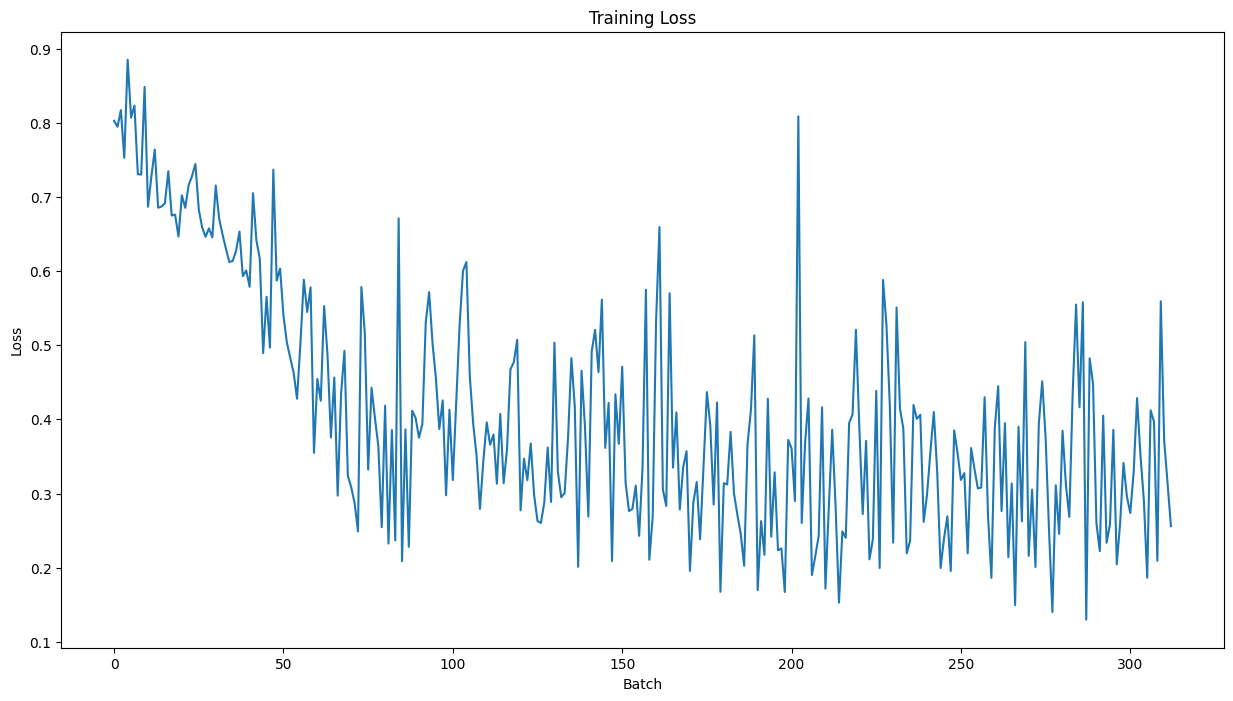

In [21]:
# Cell - Plot Training Loss

plt.figure(figsize=(15, 8))

plt.title("Training Loss")
plt.xlabel("Batch")
plt.ylabel("Loss")

plt.plot(train_loss_set)

plt.show()